# Activity 2: Binary Classification using Logistic Regression

## Objective
Build a Logistic Regression model for a binary classification problem.
Convert predicted probabilities into class labels, evaluate the model using
classification metrics, compare decision thresholds, and recommend a threshold.

## Dataset
Breast Cancer Wisconsin Diagnostic dataset from scikit-learn.

## Class definition
- Positive class (1): Malignant
- Negative class (0): Benign

## Important note
This notebook is for educational purposes only. It must not be used to make
medical decisions or diagnose patients.

In [ ]:
# Import libraries required for data handling, modelling, evaluation, and plotting

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    mean_squared_error
)

from sklearn.dummy import DummyClassifier

sns.set_theme(style="whitegrid")

In [4]:
# Load the Breast Cancer Wisconsin Diagnostic dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)

# Original scikit-learn labels:
# 0 = malignant, 1 = benign
# Convert labels so malignant is the positive class (1)
y = (data.target == 0).astype(int)

# Combine features and target into one DataFrame
df = X.copy()
df["diagnosis"] = y

print("Dataset shape:", df.shape)
print("\nFeature names:")
print(list(X.columns))

print("\nTarget definition:")
print("1 = Malignant")
print("0 = Benign")

df.head()

Dataset shape: (569, 31)

Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target definition:
1 = Malignant
0 = Benign


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [5]:
# Display data types, summary statistics, missing values, duplicates, and labels

print("Data types:")
print(df.dtypes)

print("\nSummary statistics:")
display(df.describe().T)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nTarget labels:")
print(df["diagnosis"].value_counts().sort_index())

Data types:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst sy

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Missing values in each column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
diagnosis                  0
dtype: int64

Number of duplicate rows: 0

Target labels:
diagnosis
0

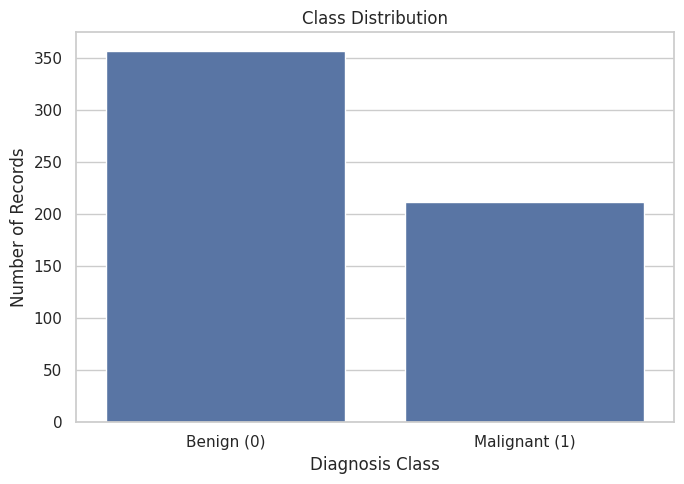

Class counts:
Benign (0): 357
Malignant (1): 212


In [6]:
# Plot the number of records in each class

class_counts = df["diagnosis"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=["Benign (0)", "Malignant (1)"],
    y=[class_counts.get(0, 0), class_counts.get(1, 0)]
)

plt.title("Class Distribution")
plt.xlabel("Diagnosis Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print("Class counts:")
print("Benign (0):", class_counts.get(0, 0))
print("Malignant (1):", class_counts.get(1, 0))

In [7]:
# Separate features and target
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

# Use a stratified 80:20 split to preserve class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining class counts:")
print(y_train.value_counts().sort_index())

print("\nTesting class counts:")
print(y_test.value_counts().sort_index())

Training observations: 455
Testing observations: 114

Training class counts:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing class counts:
diagnosis
0    72
1    42
Name: count, dtype: int64


## Why not Linear Regression?

Linear Regression predicts continuous values and can produce values below 0
or above 1. These values are not suitable as class probabilities.

Logistic Regression uses the sigmoid function to convert a score into a
probability between 0 and 1:

sigmoid(z) = 1 / (1 + exp(-z))

A decision threshold converts the probability into a class label.
For example, with threshold 0.5:
- Probability >= 0.5: predict positive (malignant)
- Probability < 0.5: predict negative (benign)

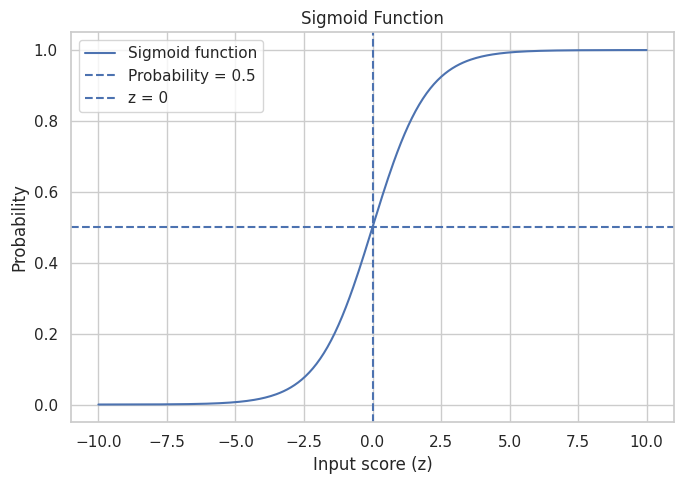

In [8]:
# Plot the sigmoid function

z = np.linspace(-10, 10, 300)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(7, 5))
plt.plot(z, sigmoid, label="Sigmoid function")
plt.axhline(0.5, linestyle="--", label="Probability = 0.5")
plt.axvline(0, linestyle="--", label="z = 0")

plt.title("Sigmoid Function")
plt.xlabel("Input score (z)")
plt.ylabel("Probability")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# Build a pipeline:
# 1. StandardScaler learns scaling values from training data only
# 2. Logistic Regression learns the classification model

model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=5000))
])

# Train using only the training set
model.fit(X_train, y_train)

print("Model settings:")
print(model.named_steps["logistic_regression"])
print("\nModel training completed.")

Model settings:
LogisticRegression(max_iter=5000)

Model training completed.


In [10]:
# Display the learned intercept and coefficient for every feature

logistic_model = model.named_steps["logistic_regression"]

print("Intercept:")
print(logistic_model.intercept_[0])

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

coefficients["Direction"] = np.where(
    coefficients["Coefficient"] > 0,
    "Positive",
    "Negative"
)

display(coefficients.sort_values("Coefficient", ascending=False))

Intercept:
-0.2430053269056021


,Feature,Coefficient,Direction
21,worst texture,1.434093,Positive
10,radius error,1.233325,Positive
28,worst symmetry,1.061264,Positive
7,mean concave points,0.952813,Positive
26,worst concavity,0.911406,Positive
13,area error,0.909029,Positive
23,worst area,0.900477,Positive
20,worst radius,0.896968,Positive
6,mean concavity,0.782298,Positive
12,perimeter error,0.748295,Positive


## Coefficient interpretation

A positive coefficient means that an increase in that feature is associated
with higher odds of the positive class (malignant), when other features are
held constant.

A negative coefficient means that an increase in that feature is associated
with lower odds of the positive class, when other features are held constant.

The features are scaled, so the coefficients describe changes relative to
the scaled feature values. Coefficients show association, not causation.

In [11]:
# Obtain predicted probabilities for the positive class (malignant)
# and predicted labels using the default threshold of 0.5

y_probability = model.predict_proba(X_test)[:, 1]

threshold = 0.5
y_pred = (y_probability >= threshold).astype(int)

# Display a sample of test records
sample_predictions = X_test.head(10).copy()
sample_predictions["Actual Label"] = y_test.head(10).values
sample_predictions["Predicted Probability (Malignant)"] = y_probability[:10]
sample_predictions["Predicted Label"] = y_pred[:10]

display(sample_predictions)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Actual Label,Predicted Probability (Malignant),Predicted Label
120,11.410,10.82,73.34,403.3,0.09373,0.06685,0.03512,0.02623,0.1667,0.06113,...,510.5,0.1548,0.2390,0.21020,0.08958,0.3016,0.08523,0,0.000365,0
250,20.940,23.56,138.90,1364.0,0.10070,0.16060,0.27120,0.13100,0.2205,0.05898,...,2010.0,0.1211,0.3172,0.69910,0.21050,0.3126,0.07849,1,1.000000,1
375,16.170,16.07,106.30,788.5,0.09880,0.14380,0.06651,0.05397,0.1990,0.06572,...,861.5,0.1235,0.2550,0.21140,0.12510,0.3153,0.08960,0,0.042568,0
99,14.420,19.77,94.48,642.5,0.09752,0.11410,0.09388,0.05839,0.1879,0.06390,...,826.4,0.1431,0.3026,0.31940,0.15650,0.2718,0.09353,1,0.576187,1
455,13.380,30.72,86.34,557.2,0.09245,0.07426,0.02819,0.03264,0.1375,0.06016,...,705.6,0.1172,0.1421,0.07003,0.07763,0.2196,0.07675,0,0.509155,1
318,9.042,18.90,60.07,244.5,0.09968,0.19720,0.19750,0.04908,0.2330,0.08743,...,297.1,0.1221,0.3748,0.46090,0.11450,0.3135,0.10550,0,0.000616,0
39,13.480,20.82,88.40,559.2,0.10160,0.12550,0.10630,0.05439,0.1720,0.06419,...,740.4,0.1610,0.4225,0.50300,0.22580,0.2807,0.10710,1,0.761534,1
371,15.190,13.21,97.65,711.8,0.07963,0.06934,0.03393,0.02657,0.1721,0.05544,...,819.1,0.1126,0.1737,0.13620,0.08178,0.2487,0.06766,0,0.001012,0
98,11.600,12.84,74.34,412.6,0.08983,0.07525,0.04196,0.03350,0.1620,0.06582,...,512.5,0.1431,0.1851,0.19220,0.08449,0.2772,0.08756,0,0.000569,0
502,12.540,16.32,81.25,476.3,0.11580,0.10850,0.05928,0.03279,0.1943,0.06612,...,552.0,0.1580,0.1751,0.18890,0.08411,0.3155,0.07538,0,0.010768,0


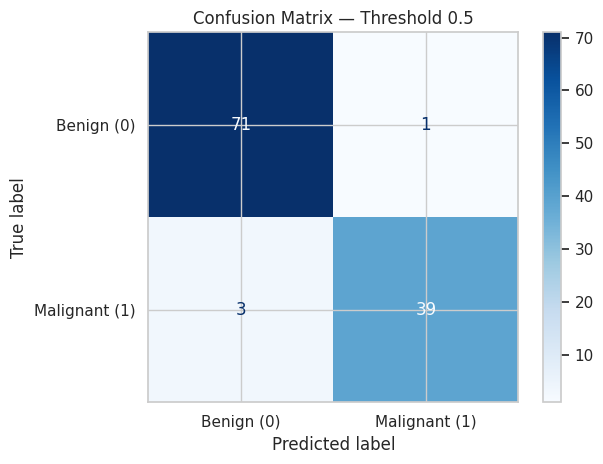

True Negative (TN): 71
False Positive (FP): 1
False Negative (FN): 3
True Positive (TP): 39


In [12]:
# Create confusion matrix with label order:
# 0 = benign, 1 = malignant

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign (0)", "Malignant (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Threshold 0.5")
plt.tight_layout()
plt.show()

# Extract TN, FP, FN, TP from the matrix
tn, fp, fn, tp = cm.ravel()

print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

## Confusion matrix interpretation

- True Positive (TP): A malignant case correctly predicted as malignant.
- False Positive (FP): A benign case incorrectly predicted as malignant.
- False Negative (FN): A malignant case incorrectly predicted as benign.
- True Negative (TN): A benign case correctly predicted as benign.

For this example, a false negative is the more serious error because a
malignant case could be missed. This is a classroom interpretation, not
medical advice.

In [13]:
# Calculate test-set classification metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall (Sensitivity)",
        "Specificity",
        "F1-score",
        "ROC-AUC"
    ],
    "Formula / Meaning": [
        "(TP + TN) / (TP + TN + FP + FN)",
        "TP / (TP + FP)",
        "TP / (TP + FN)",
        "TN / (TN + FP)",
        "2 × Precision × Recall / (Precision + Recall)",
        "Area under the ROC curve"
    ],
    "Test Set Result": [
        accuracy,
        precision,
        recall,
        specificity,
        f1,
        roc_auc
    ]
})

display(results)

,Metric,Formula / Meaning,Test Set Result
0,Accuracy,(TP + TN) / (TP + TN + FP + FN),0.964912
1,Precision,TP / (TP + FP),0.975000
2,Recall (Sensitivity),TP / (TP + FN),0.928571
3,Specificity,TN / (TN + FP),0.986111
4,F1-score,2 × Precision × Recall / (Precision + Recall),0.951220
5,ROC-AUC,Area under the ROC curve,0.996032


In [14]:
# Show precision, recall, F1-score, and support for both classes

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benign (0)", "Malignant (1)"],
    zero_division=0
))

               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114



In [15]:
# Train a baseline that always predicts the most common class in the training set

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_precision = precision_score(
    y_test, baseline_pred, zero_division=0
)
baseline_recall = recall_score(
    y_test, baseline_pred, zero_division=0
)
baseline_f1 = f1_score(
    y_test, baseline_pred, zero_division=0
)

baseline_results = pd.DataFrame({
    "Model": ["Majority-class baseline", "Logistic Regression (threshold 0.5)"],
    "Accuracy": [
        baseline_accuracy,
        accuracy_score(y_test, y_pred)
    ],
    "Precision": [
        baseline_precision,
        precision_score(y_test, y_pred, zero_division=0)
    ],
    "Recall": [
        baseline_recall,
        recall_score(y_test, y_pred, zero_division=0)
    ],
    "F1-score": [
        baseline_f1,
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

display(baseline_results)

,Model,Accuracy,Precision,Recall,F1-score
0,Majority-class baseline,0.631579,0.000,0.000000,0.00000
1,Logistic Regression (threshold 0.5),0.964912,0.975,0.928571,0.95122


## Baseline interpretation

The majority-class baseline always predicts the most common class. It gives
a simple reference point. Accuracy alone can be misleading when one class
is much more common, because a model may achieve high accuracy while failing
to identify many positive cases.

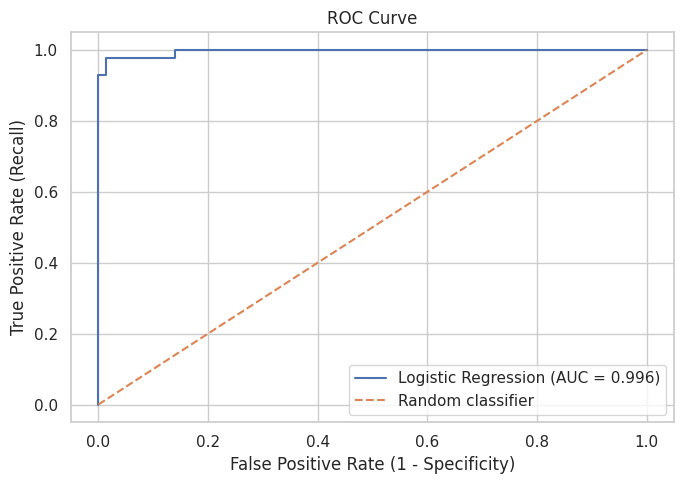

ROC-AUC: 0.996031746031746


In [16]:
# Plot ROC curve using predicted probabilities

fpr, tpr, roc_thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.title("ROC Curve")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.tight_layout()
plt.show()

print("ROC-AUC:", roc_auc)

In [17]:
# Compare performance at different decision thresholds

thresholds = [0.3, 0.5, 0.7]
threshold_rows = []

for t in thresholds:
    pred_at_t = (y_probability >= t).astype(int)

    threshold_rows.append({
        "Threshold": t,
        "Predicted Positive": int(pred_at_t.sum()),
        "Accuracy": accuracy_score(y_test, pred_at_t),
        "Precision": precision_score(
            y_test, pred_at_t, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred_at_t, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred_at_t, zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results)

,Threshold,Predicted Positive,Accuracy,Precision,Recall,F1-score
0,0.3,42,0.982456,0.97619,0.976190,0.97619
1,0.5,40,0.964912,0.97500,0.928571,0.95122
2,0.7,38,0.964912,1.00000,0.904762,0.95000


## Threshold comparison

A lower threshold usually predicts more records as positive. This can increase
recall, but it may also increase false positives and reduce precision.

A higher threshold usually predicts fewer records as positive. This can improve
precision, but it may increase false negatives and reduce recall.

The recommended threshold should reflect the relative cost of false positives
and false negatives. Do not choose a threshold based only on accuracy.

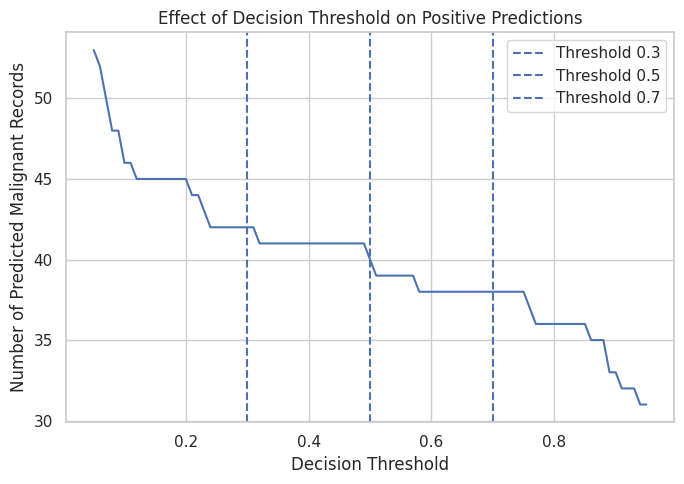

In [18]:
# Show how the number of predicted positive records changes with threshold

threshold_range = np.linspace(0.05, 0.95, 91)
positive_counts = [
    int((y_probability >= t).sum())
    for t in threshold_range
]

plt.figure(figsize=(7, 5))
plt.plot(threshold_range, positive_counts)
plt.axvline(0.3, linestyle="--", label="Threshold 0.3")
plt.axvline(0.5, linestyle="--", label="Threshold 0.5")
plt.axvline(0.7, linestyle="--", label="Threshold 0.7")

plt.title("Effect of Decision Threshold on Positive Predictions")
plt.xlabel("Decision Threshold")
plt.ylabel("Number of Predicted Malignant Records")
plt.legend()
plt.tight_layout()
plt.show()

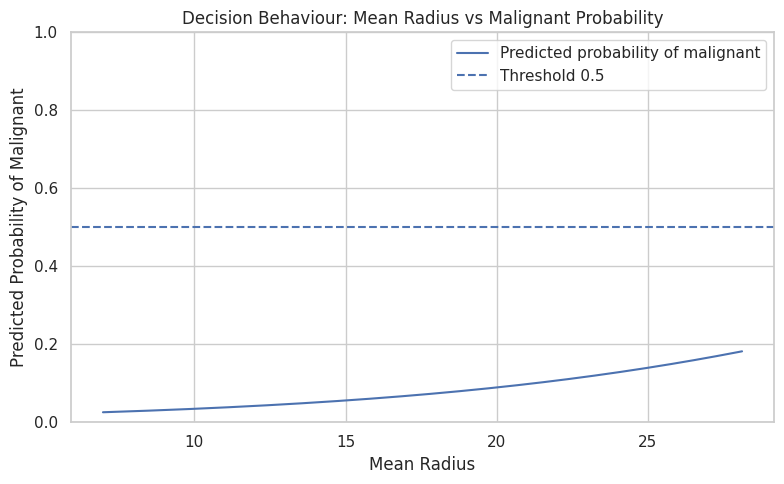

In [19]:
# Plot predicted probability against one feature.
# Other features are held at their training-set median values.

feature_name = "mean radius"

feature_values = np.linspace(
    X_train[feature_name].min(),
    X_train[feature_name].max(),
    200
)

reference_record = X_train.median()

plot_data = pd.DataFrame(
    [reference_record] * len(feature_values),
    columns=X_train.columns
)

plot_data[feature_name] = feature_values

plot_probabilities = model.predict_proba(plot_data)[:, 1]

plt.figure(figsize=(8, 5))
plt.plot(
    feature_values,
    plot_probabilities,
    label="Predicted probability of malignant"
)
plt.axhline(0.5, linestyle="--", label="Threshold 0.5")

plt.title("Decision Behaviour: Mean Radius vs Malignant Probability")
plt.xlabel("Mean Radius")
plt.ylabel("Predicted Probability of Malignant")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

## Decision-behaviour interpretation

The plot shows how the model's predicted probability changes as mean radius
changes, while the other features are held at their median training values.
It illustrates the model's behaviour for this particular feature setting.
It does not prove that mean radius alone determines the diagnosis.

In [20]:
# Compare training-set and test-set metrics to look for possible overfitting

train_probability = model.predict_proba(X_train)[:, 1]
train_pred = (train_probability >= 0.5).astype(int)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

train_f1 = f1_score(y_train, train_pred, zero_division=0)
test_f1 = f1_score(y_test, y_pred, zero_division=0)

train_test_results = pd.DataFrame({
    "Dataset": ["Training set", "Test set"],
    "Accuracy": [train_accuracy, test_accuracy],
    "F1-score": [train_f1, test_f1]
})

display(train_test_results)

,Dataset,Accuracy,F1-score
0,Training set,0.986813,0.982036
1,Test set,0.964912,0.951220


## Training and test comparison

If training performance is much higher than test performance, the model may
be overfitting. If both are low, the model may be underfitting. Similar
training and test results suggest that the model generalises more consistently,
although performance should still be checked on other data.

In [21]:
# Create a new example using median feature values from the training set.
# This is a demonstration record, not a real patient record.

new_record = X_train.median().to_frame().T

new_probability = model.predict_proba(new_record)[0, 1]
recommended_threshold = 0.5
new_label = int(new_probability >= recommended_threshold)

print("New example: median feature values from the training set")
print("Predicted probability of malignant:", new_probability)
print("Decision threshold:", recommended_threshold)

if new_label == 1:
    print("Predicted class: Malignant (1)")
else:
    print("Predicted class: Benign (0)")

New example: median feature values from the training set
Predicted probability of malignant: 0.047635125105857275
Decision threshold: 0.5
Predicted class: Benign (0)


In [22]:
# Summarise the main results at the default threshold of 0.5

print("ACTIVITY 2: BINARY CLASSIFICATION RESULTS")
print("------------------------------------------")
print("Dataset: Breast Cancer Wisconsin Diagnostic")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Positive class: Malignant (1)")
print("Negative class: Benign (0)")
print()
print("Confusion Matrix:")
print(cm)
print()
print("TN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)
print()
print(f"Accuracy:    {accuracy:.4f}")
print(f"Precision:   {precision:.4f}")
print(f"Recall:      {recall:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"F1-score:    {f1:.4f}")
print(f"ROC-AUC:     {roc_auc:.4f}")

ACTIVITY 2: BINARY CLASSIFICATION RESULTS
------------------------------------------
Dataset: Breast Cancer Wisconsin Diagnostic
Training records: 455
Testing records: 114
Positive class: Malignant (1)
Negative class: Benign (0)

Confusion Matrix:
[[71  1]
 [ 3 39]]

TN: 71 | FP: 1 | FN: 3 | TP: 39

Accuracy:    0.9649
Precision:   0.9750
Recall:      0.9286
Specificity: 0.9861
F1-score:    0.9512
ROC-AUC:     0.9960


## Decision Log

1. Problem framing:
   The model predicts whether a record is malignant or benign.
   Malignant is treated as the positive class.

2. Important metric:
   Recall is important in this example because a false negative means
   a malignant record is missed. Precision is also considered because
   false positives can lead to unnecessary follow-up.

3. Threshold recommendation:
   I compared thresholds 0.3, 0.5, and 0.7 using the test-set results.
   I recommend threshold ______ because __________________________.
   This accepts the trade-off of _________________________________.

4. Limitations:
   This is a small, public educational dataset. The model may not perform
   equally well on other populations or real-world data. It must not be
   used as a standalone medical decision system.

## Conclusion

Logistic Regression was trained on the Breast Cancer Wisconsin Diagnostic
dataset. The data was split using stratification, and numerical features
were scaled using training data only. The model produced probabilities and
class labels, and was evaluated using the confusion matrix, accuracy,
precision, recall, specificity, F1-score, ROC-AUC, and a majority-class
baseline.

The threshold was compared using test-set results. A model prediction is a
probability-based estimate, not a guaranteed outcome.